# **실습 개요**

여러분은 이커머스 기업의 **마케팅 데이터 분석가**입니다. <br>
회사는 매달 모바일 광고, SNS 광고, 오프라인(매장) 채널에 마케팅 예산과 인력을 투입하고 있고, <br>
이 활동이 실제 **멤버십 가입**으로 이어지는지를 예측하는 모델을 만들려고 합니다.

다만 모바일 광고비와 SNS 광고비는 같은 캠페인 기간에 함께 늘고 줄어드는 경향이 있어 <br>
강한 상관관계(다중공선성)를 갖고 있습니다. 이런 상황에서 변수를 어떻게 다루느냐에 따라 모델의 신뢰도와 성능이 달라집니다.

## **데이터셋 설명**

25개 시점(캠페인 단위) 동안의 채널별 마케팅 지표와 실제 멤버십 가입 여부를 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| mobile | 모바일 광고비 |
| sns | SNS 광고비 |
| offline | 오프라인(매장) 방문자 수 (명) |
| membership | **[target]** 멤버십 가입 여부 (1=가입, 0=미가입) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/ad.csv

## **1. 데이터 살펴보기**

**Q1. 데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/ad.csv")
df.head()

,mobile,sns,offline,membership
0,551.4,567.9,2122,0
1,258.4,230.4,2104,0
2,377.3,296.7,4632,0
3,584.3,452.3,3028,1
4,729.1,662.4,3068,1


## **2. 데이터 분리하기**

**Q1. 'membership'을 라벨로 데이터를 train과 test 데이터로 분리하세요.**
- 비율: 7(학습):3(테스트)
- random_state = 32
- stratify 옵션을 사용합니다.

In [8]:
from sklearn.model_selection import train_test_split

# X = df.drop("membership", axis=1)

X = df.drop(columns='membership')
y = df['membership']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=32, stratify=y)

## **3. 모델링 1**

**Q1. 로지스틱 회귀 모델을 생성하고, 학습시킵니다.**

In [9]:
from sklearn.linear_model import LogisticRegression

model_lg = LogisticRegression()

model_lg.fit(X_tr, y_tr)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

**Q2. 학습된 모델로 테스트 데이터의 값을 예측합니다.**

In [10]:
y_pred = model_lg.predict(X_te)

**Q3. 모델을 평가합니다.**

0.875 

              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.75      0.86         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



<Axes: >

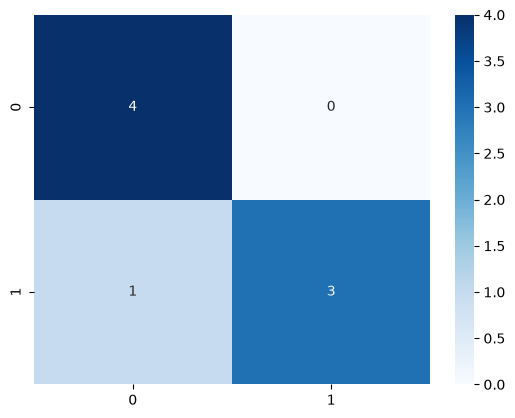

In [24]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_te, y_pred), '\n')

from sklearn.metrics import classification_report
print(classification_report(y_te, y_pred))

from sklearn.metrics import confusion_matrix
sns.heatmap(confusion_matrix(y_te, y_pred), annot=True, cmap='Blues')

## **3. 다중공선성 확인하기**

**Q1. train 데이터의 상관행렬을 시각화하세요.**

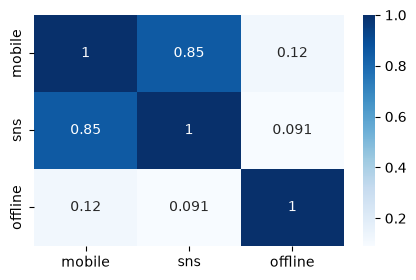

In [26]:
# code here

# 상관행렬 (correlation matrix) : 각 변수간의 관계를 보기 위해 사용하는 시각화 (통계)
# 라벨 없이 보게 되면 -> 각 변수끼리 얼마나 큰 영향을 미치는지를 확인할 수 있다.
# 좋은 데이터 : 모든 특징이 최대한 독립적이여야 좋다.ㅇ

# 상관행렬의 결과 
# 1 : 완벽 비례 
# 0 : 관계 없음
# -1 :완벽 반비례 

# 공선성의 판단 기준
# 0~0.5 : 크게 신경쓸 필요 없다. 
# 0.5~0.7 : 둘이 그래도 꽤 서로 영향이 있는 관계다
# 0.7~ : 둘이 아주 높은 상관관계에 있다 -> 다중공선성이라는것을 의심 해야 한다.

# 다중공선성 : multicolinearity 
# 하나의 변수를 가지고 다른 변수의 값을 예측 가능한 상황
# perfect muliticolinearity : 완벽하게 예측이 가능한 상황 -> one hot encoding (drop 하는 이유)
# multicolinearity를 처리해야하는 이유 : 같은 변수 -> 너무 발언권이 심해짐 
# 특히나 선형 모델이나 연속적인 값 (regression) 을 처리해야하는 경우에는 필수

plt.figure(figsize=(5, 3))
sns.heatmap(X_tr.corr(), annot=True, cmap="Blues")
plt.show() 

**Q2. train 데이터와 라벨까지 포함한 상관행렬을 시각화하세요.**

<Axes: >

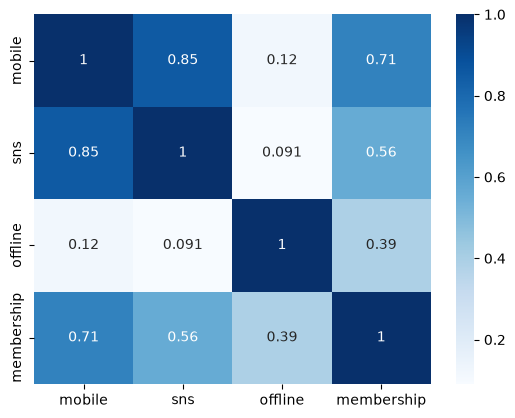

In [32]:
Xy_train_set = pd.concat([X_tr, y_tr], axis=1)

sns.heatmap(Xy_train_set.corr(), annot=True, cmap='Blues')

## **모델링 2**

**Q1. 상관관계가 높은 컬럼 중 하나를 드랍합니다.**
- 드랍시에는 상관 관계가 있는 두 특징 중, 결과에 영향을 덜 끼치는 컬럼을 드랍합니다.

In [33]:
X_tr = X_tr.drop(columns='sns')
X_te = X_te.drop(columns='sns')

**Q2. 로지스틱 회귀 모델을 학습 시킵니다.**

In [34]:
from sklearn.linear_model import LogisticRegression

model_lg = LogisticRegression()
model_lg.fit(X_tr, y_tr)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

**Q3. 학습된 모델로 test 데이터의 예측 결과를 구합니다.**

In [35]:
y_pred = model_lg.predict(X_te)

**Q4. 모델의 성능을 평가합니다.**

1.0 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



<Axes: >

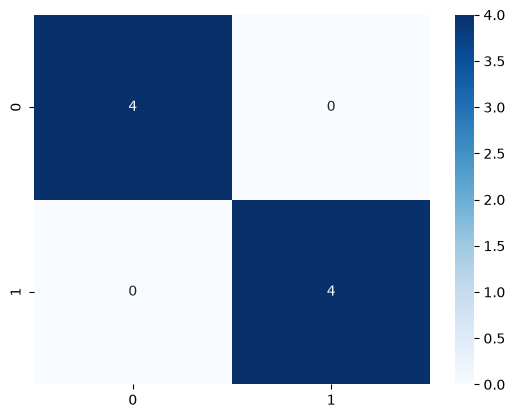

In [36]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_te, y_pred), '\n')

from sklearn.metrics import classification_report
print(classification_report(y_te, y_pred))

from sklearn.metrics import confusion_matrix
sns.heatmap(confusion_matrix(y_te, y_pred), annot=True, cmap='Blues')